In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 2.24.15 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/images_9.jpg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 2.24.32 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 12.18.57 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 12.19.16 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 12.19.56 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 12.19.34 PM.jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Fraudulent/WhatsApp Image 2026-09-13 at 12.19.42 PM (1).jpeg
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/Fi

In [2]:
# ============================================
# FinGuard AI - QR Authenticity Detection
# Fresh Notebook Setup
# ============================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import hashlib

BASE_PATH = "/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR"

print("Dataset path:")
print(BASE_PATH)

print("\nPath exists:", os.path.exists(BASE_PATH))

if os.path.exists(BASE_PATH):
    print("\nContents:")
    for item in os.listdir(BASE_PATH):
        print(" -", item)
else:
    print("\nERROR: Dataset path does not exist.")

Dataset path:
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR

Path exists: True

Contents:
 - Fraudulent
 - Authentic


In [3]:
# ============================================
# Verify dataset folders
# ============================================

AUTHENTIC_PATH = os.path.join(BASE_PATH, "Authentic")
FRAUDULENT_PATH = os.path.join(BASE_PATH, "Fraudulent")

print("Authentic path exists :", os.path.exists(AUTHENTIC_PATH))
print("Fraudulent path exists:", os.path.exists(FRAUDULENT_PATH))

print("\nAuthentic files:", len(os.listdir(AUTHENTIC_PATH)))
print("Fraudulent files:", len(os.listdir(FRAUDULENT_PATH)))

Authentic path exists : True
Fraudulent path exists: True

Authentic files: 198
Fraudulent files: 210


In [4]:
# ============================================
# Build QR dataset dataframe
# ============================================

records = []

for class_name in ["Authentic", "Fraudulent"]:
    
    class_path = os.path.join(BASE_PATH, class_name)
    
    for filename in os.listdir(class_path):
        
        filepath = os.path.join(class_path, filename)
        
        if os.path.isfile(filepath):
            records.append({
                "path": filepath,
                "filename": filename,
                "class": class_name
            })

qr_df = pd.DataFrame(records)

print("Total images:", len(qr_df))

print("\nClass distribution:")
print(qr_df["class"].value_counts())

print("\nFirst 10 records:")
display(qr_df.head(10))

Total images: 408

Class distribution:
class
Fraudulent    210
Authentic     198
Name: count, dtype: int64

First 10 records:


,path,filename,class
0,/kaggle/input/datasets/pmaheswarraju/finguard-...,real_68.jpeg,Authentic
1,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_4883.HEIC,Authentic
2,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_4889(1).HEIC,Authentic
3,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_4925.HEIC,Authentic
4,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_7002.HEIC,Authentic
5,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_4938.HEIC,Authentic
6,/kaggle/input/datasets/pmaheswarraju/finguard-...,real_69.jpeg,Authentic
7,/kaggle/input/datasets/pmaheswarraju/finguard-...,IMG_4890.HEIC,Authentic
8,/kaggle/input/datasets/pmaheswarraju/finguard-...,real_4.jpg,Authentic
9,/kaggle/input/datasets/pmaheswarraju/finguard-...,real_45.jpeg,Authentic


In [5]:
# ============================================
# File extension analysis
# ============================================

qr_df["extension"] = qr_df["filename"].apply(
    lambda x: os.path.splitext(x)[1].lower()
)

print("Extension distribution:")
print(qr_df["extension"].value_counts())

print("\nExtension distribution by class:")
print(
    pd.crosstab(
        qr_df["class"],
        qr_df["extension"]
    )
)

Extension distribution:
extension
.jpeg    240
.heic     80
.jpg      79
.png       9
Name: count, dtype: int64

Extension distribution by class:
extension   .heic  .jpeg  .jpg  .png
class                               
Authentic      80     43    66     9
Fraudulent      0    197    13     0


In [6]:
# ============================================
# Check whether images can be opened
# ============================================

valid_images = []
failed_images = []

for _, row in qr_df.iterrows():
    
    try:
        with Image.open(row["path"]) as img:
            img.verify()
        
        valid_images.append(row["path"])
        
    except Exception as e:
        failed_images.append({
            "path": row["path"],
            "error": str(e)
        })

print("Total images :", len(qr_df))
print("Valid images :", len(valid_images))
print("Failed images:", len(failed_images))

if failed_images:
    print("\nFirst failed images:")
    for item in failed_images[:20]:
        print(item["path"])
        print("Error:", item["error"])

Total images : 408
Valid images : 328
Failed images: 80

First failed images:
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4883.HEIC
Error: cannot identify image file '/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4883.HEIC'
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4889(1).HEIC
Error: cannot identify image file '/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4889(1).HEIC'
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4925.HEIC
Error: cannot identify image file '/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_4925.HEIC'
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_7002.HEIC
Error: cannot identify image file '/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuard_QR/Authentic/IMG_7002.HEIC'
/kaggle/input/datasets/pmaheswarraju/finguard-ai-qr1/FinGuar

In [7]:
!pip install -q pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 14.5 MB/s eta 0:00:0000:0100:01


In [8]:
# ============================================
# Convert HEIC -> JPEG
# ============================================

from pillow_heif import register_heif_opener
from PIL import Image
import os

register_heif_opener()

CONVERTED_DIR = "/kaggle/working/FinGuard_QR_Converted"

os.makedirs(
    os.path.join(CONVERTED_DIR, "Authentic"),
    exist_ok=True
)

os.makedirs(
    os.path.join(CONVERTED_DIR, "Fraudulent"),
    exist_ok=True
)

converted_records = []

for _, row in qr_df.iterrows():

    source_path = row["path"]
    class_name = row["class"]
    filename = row["filename"]

    extension = os.path.splitext(filename)[1].lower()

    try:

        if extension == ".heic":

            # Change extension to JPG
            new_filename = os.path.splitext(filename)[0] + ".jpg"

            output_path = os.path.join(
                CONVERTED_DIR,
                class_name,
                new_filename
            )

            img = Image.open(source_path).convert("RGB")

            img.save(
                output_path,
                "JPEG",
                quality=95
            )

        else:

            # Keep original readable image
            output_path = source_path

        converted_records.append({
            "path": output_path,
            "filename": os.path.basename(output_path),
            "class": class_name
        })

    except Exception as e:

        print("FAILED:")
        print(source_path)
        print("Error:", e)


converted_df = pd.DataFrame(converted_records)

print("=" * 60)
print("CONVERSION COMPLETE")
print("=" * 60)

print("Original images:", len(qr_df))
print("Successfully processed:", len(converted_df))
print("Failed:", len(qr_df) - len(converted_df))

print("\nClass distribution:")
print(converted_df["class"].value_counts())

CONVERSION COMPLETE
Original images: 408
Successfully processed: 408
Failed: 0

Class distribution:
class
Fraudulent    210
Authentic     198
Name: count, dtype: int64


In [9]:
# ============================================
# Verify converted images
# ============================================

heic_originals = qr_df[
    qr_df["filename"].str.lower().str.endswith(".heic")
]

converted_heic = converted_df[
    converted_df["filename"].str.lower().str.endswith(".jpg")
]

print("Original HEIC files:", len(heic_originals))
print("Converted HEIC files:", len(converted_heic))

failed_conversion = []

for _, row in converted_heic.iterrows():

    try:
        with Image.open(row["path"]) as img:
            img.verify()

    except Exception as e:
        failed_conversion.append({
            "path": row["path"],
            "error": str(e)
        })

print("Failed converted files:", len(failed_conversion))

if failed_conversion:
    for item in failed_conversion[:20]:
        print(item)

Original HEIC files: 80
Converted HEIC files: 159
Failed converted files: 0


In [10]:
# ============================================
# Final readability check
# ============================================

valid_records = []
failed_records = []

for _, row in converted_df.iterrows():

    try:

        with Image.open(row["path"]) as img:
            img.verify()

        valid_records.append(row)

    except Exception as e:

        failed_records.append({
            "path": row["path"],
            "class": row["class"],
            "error": str(e)
        })


final_df = pd.DataFrame(valid_records).reset_index(drop=True)

print("=" * 60)
print("FINAL READABILITY CHECK")
print("=" * 60)

print("Original:", len(qr_df))
print("Readable:", len(final_df))
print("Failed:", len(failed_records))

print("\nClass distribution:")
print(final_df["class"].value_counts())

print("\nExtensions:")
print(
    final_df["filename"]
    .apply(lambda x: os.path.splitext(x)[1].lower())
    .value_counts()
)

FINAL READABILITY CHECK
Original: 408
Readable: 408
Failed: 0

Class distribution:
class
Fraudulent    210
Authentic     198
Name: count, dtype: int64

Extensions:
filename
.jpeg    240
.jpg     159
.png       9
Name: count, dtype: int64


In [11]:
# ============================================
# Exact duplicate check on decoded images
# ============================================

import hashlib
from PIL import Image
import numpy as np
from collections import defaultdict

image_hashes = {}
hash_groups = defaultdict(list)

for _, row in final_df.iterrows():

    path = row["path"]

    try:
        img = Image.open(path).convert("RGB")

        # Normalize to a fixed size before hashing
        img = img.resize((256, 256))

        pixel_data = np.array(img).tobytes()
        file_hash = hashlib.md5(pixel_data).hexdigest()

        image_hashes[path] = file_hash
        hash_groups[file_hash].append(path)

    except Exception as e:
        print("Failed:", path, e)

duplicate_groups = [
    files for files in hash_groups.values()
    if len(files) > 1
]

duplicate_count = sum(len(g) - 1 for g in duplicate_groups)

print("=" * 60)
print("EXACT VISUAL DUPLICATE CHECK")
print("=" * 60)

print("Total readable images:", len(final_df))
print("Unique image contents:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Duplicate copies:", duplicate_count)

if duplicate_groups:
    print("\nFirst 20 duplicate groups:")

    for i, group in enumerate(duplicate_groups[:20], start=1):

        print(f"\nGroup {i}:")

        for path in group:
            print(" ", os.path.basename(path))

EXACT VISUAL DUPLICATE CHECK
Total readable images: 408
Unique image contents: 338
Duplicate groups: 70
Duplicate copies: 70

First 20 duplicate groups:

Group 1:
  IMG_4883.jpg
  IMG_4883(1).jpg

Group 2:
  IMG_4889(1).jpg
  IMG_4889.jpg

Group 3:
  IMG_7002.jpg
  IMG_4625.jpg

Group 4:
  IMG_4920.jpg
  IMG_4920(1).jpg

Group 5:
  IMG_4924.jpg
  IMG_7000.jpg

Group 6:
  F1E5DF82-2780-4D2F-B87A-3060F7A5D401.jpg
  F1E5DF82-2780-4D2F-B87A-3060F7A5D401(1).jpg

Group 7:
  IMG_4876(1).jpg
  IMG_4876.jpg

Group 8:
  IMG_293.PNG
  IMG_2934.PNG

Group 9:
  IMG_5001(1).JPG
  IMG_5001.JPG

Group 10:
  IMG_2904.PNG
  IMG_290.PNG

Group 11:
  0AC641EF-D637-4733-88B0-D906D3B8219B.jpg
  0AC641EF-D637-4733-88B0-D906D3B8219B(1).jpg

Group 12:
  img_7732.jpg
  IMG_4877.jpg

Group 13:
  IMG_4879.jpg
  IMG_6000.jpg

Group 14:
  IMG_4873.jpg
  IMG_7005.jpg

Group 15:
  real_56.jpeg
  real_43.jpeg

Group 16:
  IMG_4915(1).jpg
  IMG_4915.jpg

Group 17:
  real_13.jpg
  real_12.jpg

Group 18:
  real_21.jpg
  

In [12]:
# ============================================
# Remove exact visual duplicate copies
# ============================================

seen_hashes = set()
unique_records = []

for _, row in final_df.iterrows():

    path = row["path"]
    file_hash = image_hashes.get(path)

    if file_hash is None:
        continue

    if file_hash not in seen_hashes:

        seen_hashes.add(file_hash)
        unique_records.append(row)

qr_unique_df = pd.DataFrame(unique_records).reset_index(drop=True)

print("=" * 60)
print("CLEAN QR DATASET")
print("=" * 60)

print("Original images:", len(final_df))
print("Unique images:", len(qr_unique_df))
print("Removed duplicates:", len(final_df) - len(qr_unique_df))

print("\nClass distribution:")
print(qr_unique_df["class"].value_counts())

print("\nClass percentages:")
print(
    (qr_unique_df["class"].value_counts(normalize=True) * 100)
    .round(2)
)

CLEAN QR DATASET
Original images: 408
Unique images: 338
Removed duplicates: 70

Class distribution:
class
Fraudulent    188
Authentic     150
Name: count, dtype: int64

Class percentages:
class
Fraudulent    55.62
Authentic     44.38
Name: proportion, dtype: float64


In [13]:
# ============================================
# Perceptual hash analysis
# ============================================

!pip install -q ImageHash

In [14]:
# ============================================
# Generate perceptual hashes
# ============================================

import imagehash

phash_records = []

for _, row in qr_unique_df.iterrows():

    path = row["path"]

    try:

        img = Image.open(path).convert("RGB")

        phash = imagehash.phash(img)

        phash_records.append({
            "path": path,
            "filename": row["filename"],
            "class": row["class"],
            "phash": phash
        })

    except Exception as e:

        print("Failed:", path, e)


phash_df = pd.DataFrame(phash_records)

print("Images hashed:", len(phash_df))

Images hashed: 338


In [15]:
# ============================================
# Find near-duplicate image pairs
# ============================================

similar_pairs = []

for i in range(len(phash_df)):

    for j in range(i + 1, len(phash_df)):

        # Only compare within the same class
        if phash_df.iloc[i]["class"] != phash_df.iloc[j]["class"]:
            continue

        distance = (
            phash_df.iloc[i]["phash"]
            - phash_df.iloc[j]["phash"]
        )

        if distance <= 8:

            similar_pairs.append({
                "class": phash_df.iloc[i]["class"],
                "distance": distance,
                "image1": phash_df.iloc[i]["filename"],
                "image2": phash_df.iloc[j]["filename"],
                "path1": phash_df.iloc[i]["path"],
                "path2": phash_df.iloc[j]["path"]
            })

similar_df = pd.DataFrame(similar_pairs)

print("=" * 60)
print("NEAR-DUPLICATE ANALYSIS")
print("=" * 60)

print("Potential near-duplicate pairs:", len(similar_df))

if len(similar_df) > 0:

    display(
        similar_df[
            ["class", "distance", "image1", "image2"]
        ]
        .sort_values("distance")
        .head(100)
    )

NEAR-DUPLICATE ANALYSIS
Potential near-duplicate pairs: 69


,class,distance,image1,image2
7,Fraudulent,2,WhatsApp Image 2026-09-13 at 2.24.32 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.33 PM (1).jpeg
8,Fraudulent,2,WhatsApp Image 2026-09-13 at 2.24.32 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.33 PM (2).jpeg
26,Fraudulent,2,WhatsApp Image 2026-09-13 at 2.24.34 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.33 PM (2).jpeg
21,Fraudulent,2,WhatsApp Image 2026-09-13 at 2.24.34 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.33 PM.jpeg
53,Fraudulent,2,WhatsApp Image 2026-09-13 at 2.24.33 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.33 PM (2).jpeg
...,...,...,...,...
63,Fraudulent,8,WhatsApp Image 2026-09-13 at 2.24.25 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.26 PM.jpeg
48,Fraudulent,8,WhatsApp Image 2026-09-13 at 2.24.28 PM (2).jpeg,WhatsApp Image 2026-09-13 at 2.24.28 PM.jpeg
51,Fraudulent,8,WhatsApp Image 2026-09-13 at 2.24.33 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.35 PM.jpeg
52,Fraudulent,8,WhatsApp Image 2026-09-13 at 2.24.33 PM.jpeg,WhatsApp Image 2026-09-13 at 2.24.34 PM (3).jpeg


In [16]:
# ============================================
# Create near-duplicate groups
# ============================================

from collections import defaultdict

# Use qr_unique_df as the clean 338-image dataset
group_parent = {
    path: path
    for path in qr_unique_df["path"]
}

def find_root(path):
    while group_parent[path] != path:
        group_parent[path] = group_parent[group_parent[path]]
        path = group_parent[path]
    return path

def union_paths(path1, path2):
    root1 = find_root(path1)
    root2 = find_root(path2)

    if root1 != root2:
        group_parent[root2] = root1


# Connect near-duplicate images
for _, row in similar_df.iterrows():

    union_paths(
        row["path1"],
        row["path2"]
    )


# Assign group IDs
root_to_group = {}
group_ids = []

for path in qr_unique_df["path"]:

    root = find_root(path)

    if root not in root_to_group:
        root_to_group[root] = len(root_to_group) + 1

    group_ids.append(root_to_group[root])


qr_unique_df["group_id"] = group_ids

print("=" * 60)
print("NEAR-DUPLICATE GROUPING")
print("=" * 60)

print("Total unique images:", len(qr_unique_df))
print("Total groups:", qr_unique_df["group_id"].nunique())

print("\nGroup size distribution:")
print(
    qr_unique_df["group_id"]
    .value_counts()
    .value_counts()
    .sort_index()
)

NEAR-DUPLICATE GROUPING
Total unique images: 338
Total groups: 308

Group size distribution:
count
1     300
2       3
3       2
6       1
10      2
Name: count, dtype: int64


In [17]:
# ============================================
# Inspect groups
# ============================================

group_summary = (
    qr_unique_df
    .groupby(["group_id", "class"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

display(group_summary.head(30))

,group_id,class,image_count
173,174,Fraudulent,10
149,150,Fraudulent,10
164,165,Fraudulent,6
9,10,Authentic,3
196,197,Fraudulent,3
147,148,Fraudulent,2
86,87,Authentic,2
166,167,Fraudulent,2
211,212,Fraudulent,1
209,210,Fraudulent,1


In [18]:
# ============================================
# Show largest groups
# ============================================

largest_groups = (
    qr_unique_df["group_id"]
    .value_counts()
    .head(10)
)

print("Largest groups:")

for group_id, count in largest_groups.items():

    group = qr_unique_df[
        qr_unique_df["group_id"] == group_id
    ]

    print("\n" + "=" * 50)
    print(
        f"Group {group_id} | "
        f"Class: {group.iloc[0]['class']} | "
        f"Images: {len(group)}"
    )

    for filename in group["filename"]:
        print(" ", filename)

Largest groups:

Group 174 | Class: Fraudulent | Images: 10
  WhatsApp Image 2026-09-13 at 2.24.26 PM (1).jpeg
  WhatsApp Image 2026-09-13 at 2.24.27 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.27 PM (1).jpeg
  WhatsApp Image 2026-09-13 at 2.24.28 PM (2).jpeg
  WhatsApp Image 2026-09-13 at 2.24.27 PM (2).jpeg
  WhatsApp Image 2026-09-13 at 2.24.25 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.26 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.28 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.26 PM (2).jpeg
  WhatsApp Image 2026-09-13 at 2.24.28 PM (1).jpeg

Group 150 | Class: Fraudulent | Images: 10
  WhatsApp Image 2026-09-13 at 2.24.32 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.34 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.35 PM (1).jpeg
  WhatsApp Image 2026-09-13 at 2.24.33 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.34 PM (2).jpeg
  WhatsApp Image 2026-09-13 at 2.24.33 PM (1).jpeg
  WhatsApp Image 2026-09-13 at 2.24.35 PM.jpeg
  WhatsApp Image 2026-09-13 at 2.24.34 PM (3).jpeg
  WhatsApp

In [19]:
# ============================================
# GROUP-AWARE SPLIT - GROUP TABLE
# ============================================

from sklearn.model_selection import train_test_split

group_df = (
    qr_unique_df
    .groupby("group_id")
    .agg(
        class_label=("class", "first"),
        image_count=("path", "count")
    )
    .reset_index()
)

print("Total unique images :", len(qr_unique_df))
print("Total groups        :", len(group_df))

print("\nGroups by class:")
print(group_df["class_label"].value_counts())

print("\nImages by class:")
print(qr_unique_df["class"].value_counts())

Total unique images : 338
Total groups        : 308

Groups by class:
class_label
Fraudulent    161
Authentic     147
Name: count, dtype: int64

Images by class:
class
Fraudulent    188
Authentic     150
Name: count, dtype: int64


In [20]:
# ============================================
# SPLIT GROUPS, NOT INDIVIDUAL IMAGES
# ============================================

train_groups, temp_groups = train_test_split(
    group_df,
    test_size=0.30,
    random_state=42,
    stratify=group_df["class_label"]
)

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups["class_label"]
)

train_group_ids = set(train_groups["group_id"])
val_group_ids = set(val_groups["group_id"])
test_group_ids = set(test_groups["group_id"])

train_df = qr_unique_df[
    qr_unique_df["group_id"].isin(train_group_ids)
].copy()

val_df = qr_unique_df[
    qr_unique_df["group_id"].isin(val_group_ids)
].copy()

test_df = qr_unique_df[
    qr_unique_df["group_id"].isin(test_group_ids)
].copy()

print("=" * 60)
print("GROUP-AWARE SPLIT")
print("=" * 60)

print("\nTRAIN")
print("Groups :", len(train_group_ids))
print("Images :", len(train_df))
print(train_df["class"].value_counts())

print("\nVALIDATION")
print("Groups :", len(val_group_ids))
print("Images :", len(val_df))
print(val_df["class"].value_counts())

print("\nTEST")
print("Groups :", len(test_group_ids))
print("Images :", len(test_df))
print(test_df["class"].value_counts())

print("\nTotal images:",
      len(train_df) + len(val_df) + len(test_df))

GROUP-AWARE SPLIT

TRAIN
Groups : 215
Images : 227
class
Fraudulent    121
Authentic     106
Name: count, dtype: int64

VALIDATION
Groups : 46
Images : 55
class
Fraudulent    33
Authentic     22
Name: count, dtype: int64

TEST
Groups : 47
Images : 56
class
Fraudulent    34
Authentic     22
Name: count, dtype: int64

Total images: 338


In [21]:
# ============================================
# VERIFY GROUP LEAKAGE
# ============================================

train_groups_check = set(train_df["group_id"])
val_groups_check = set(val_df["group_id"])
test_groups_check = set(test_df["group_id"])

print("Train ∩ Validation:",
      len(train_groups_check & val_groups_check))

print("Train ∩ Test:",
      len(train_groups_check & test_groups_check))

print("Validation ∩ Test:",
      len(val_groups_check & test_groups_check))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [22]:
# ============================================
# FINAL SPLIT SUMMARY
# ============================================

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Groups": [
        len(train_group_ids),
        len(val_group_ids),
        len(test_group_ids)
    ],
    "Images": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

split_summary["Percentage"] = (
    split_summary["Images"] /
    len(qr_unique_df) * 100
).round(2)

display(split_summary)

print("\nClass distribution by split:")

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print(df["class"].value_counts())

,Split,Groups,Images,Percentage
0,Train,215,227,67.16
1,Validation,46,55,16.27
2,Test,47,56,16.57



Class distribution by split:

TRAIN
class
Fraudulent    121
Authentic     106
Name: count, dtype: int64

VALIDATION
class
Fraudulent    33
Authentic     22
Name: count, dtype: int64

TEST
class
Fraudulent    34
Authentic     22
Name: count, dtype: int64


In [23]:
# ============================================
# LABEL ENCODING + CLASS WEIGHTS
# ============================================

from sklearn.utils.class_weight import compute_class_weight

label_map = {
    "Authentic": 0,
    "Fraudulent": 1
}

train_df["label"] = train_df["class"].map(label_map)
val_df["label"] = val_df["class"].map(label_map)
test_df["label"] = test_df["class"].map(label_map)

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Label mapping:")
print(label_map)

print("\nClass weights:")
print(class_weights)

Label mapping:
{'Authentic': 0, 'Fraudulent': 1}

Class weights:
{0: np.float64(1.070754716981132), 1: np.float64(0.9380165289256198)}


In [24]:
# ============================================
# TENSORFLOW DATA PIPELINE
# ============================================

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    
    image.set_shape([None, None, 3])
    
    image = tf.image.resize(
        image,
        IMG_SIZE
    )
    
    image = tf.cast(image, tf.float32) / 255.0
    
    return image, tf.cast(label, tf.float32)


def make_dataset(df, training=False):
    
    paths = df["path"].values
    labels = df["label"].values
    
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )
    
    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )
    
    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    
    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

I0000 00:00:1789302538.133756      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Train batches: 8
Validation batches: 2
Test batches: 2


In [25]:
# ============================================
# CHECK DATA PIPELINE
# ============================================

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image min:", tf.reduce_min(images).numpy())
print("Image max:", tf.reduce_max(images).numpy())
print("Labels:", labels.numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image min: 0.0
Image max: 1.0
Labels: [0. 1. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1.
 0. 0. 0. 0. 1. 0. 1. 1.]


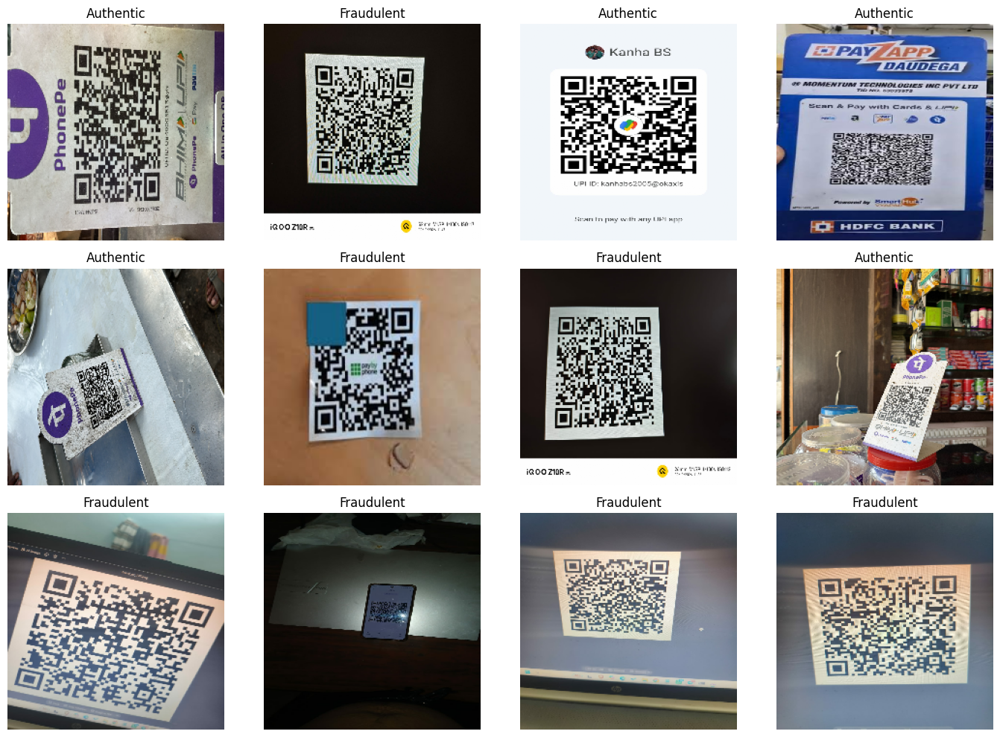

In [26]:
# ============================================
# VISUALIZE TRAINING IMAGES
# ============================================

plt.figure(figsize=(14, 10))

for i in range(min(12, len(images))):
    
    ax = plt.subplot(3, 4, i + 1)
    
    plt.imshow(images[i].numpy())
    
    label = int(labels[i].numpy())
    class_name = "Fraudulent" if label == 1 else "Authentic"
    
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# ============================================
# FinGuard AI - QR Custom CNN
# Same architecture used for other modules
# ============================================

from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="qr_augmentation")


def build_custom_cnn(input_shape=(224, 224, 3)):

    inputs = layers.Input(shape=input_shape)

    # Data augmentation
    x = data_augmentation(inputs)

    # Block 1
    x = layers.Conv2D(
        32, (3, 3),
        padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2
    x = layers.Conv2D(
        64, (3, 3),
        padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3
    x = layers.Conv2D(
        128, (3, 3),
        padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 4
    x = layers.Conv2D(
        256, (3, 3),
        padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Global feature extraction
    x = layers.GlobalAveragePooling2D()(x)

    # Classification head
    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_QR_Custom_CNN"
    )


qr_model = build_custom_cnn()

qr_model.summary()

Model: "FinGuard_QR_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ qr_augmentation (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [28]:
# ============================================
# MODEL PARAMETERS
# ============================================

total_params = qr_model.count_params()

print("Total parameters:", total_params)
print("Trainable parameters:", 
      sum(np.prod(v.shape) for v in qr_model.trainable_weights))
print("Non-trainable parameters:", 
      sum(np.prod(v.shape) for v in qr_model.non_trainable_weights))

Total parameters: 423361
Trainable parameters: 422401
Non-trainable parameters: 960


In [29]:
# ============================================
# COMPILE MODEL
# ============================================

qr_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.AUC(
            name="auc"
        ),
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [37]:
# ============================================
# CALLBACKS
# ============================================

MODEL_PATH = "/kaggle/working/finguard_qr_custom_cnn.keras"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    MODEL_PATH,
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks ready.")
print("Model will be saved to:")
print(MODEL_PATH)

Callbacks ready.
Model will be saved to:
/kaggle/working/finguard_qr_custom_cnn.keras


In [31]:
# ============================================
# TRAIN QR CUSTOM CNN
# ============================================

history = qr_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.6551 - auc: 0.7116 - loss: 0.6198 - precision: 0.7293 - recall: 0.4632
Epoch 1: val_auc improved from None to 0.39532, saving model to /kaggle/working/finguard_qr_custom_cnn.keras

Epoch 1: finished saving model to /kaggle/working/finguard_qr_custom_cnn.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 289ms/step - accuracy: 0.6916 - auc: 0.7587 - loss: 0.6047 - precision: 0.7576 - recall: 0.6198 - val_accuracy: 0.6000 - val_auc: 0.3953 - val_loss: 0.7034 - val_precision: 0.6000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.7980 - auc: 0.8598 - loss: 0.4776 - precision: 0.7965 - recall: 0.8297
Epoch 2: val_auc improved from 0.39532 to 0.82576, saving model to /kaggle/working/finguard_qr_custom_cnn.keras

Epoch 2: finished saving model to /kaggle/working/finguard_qr_custom_cnn.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 426ms/step - accuracy: 0.8018 - auc: 0.8653 - loss: 0.4609 - precis

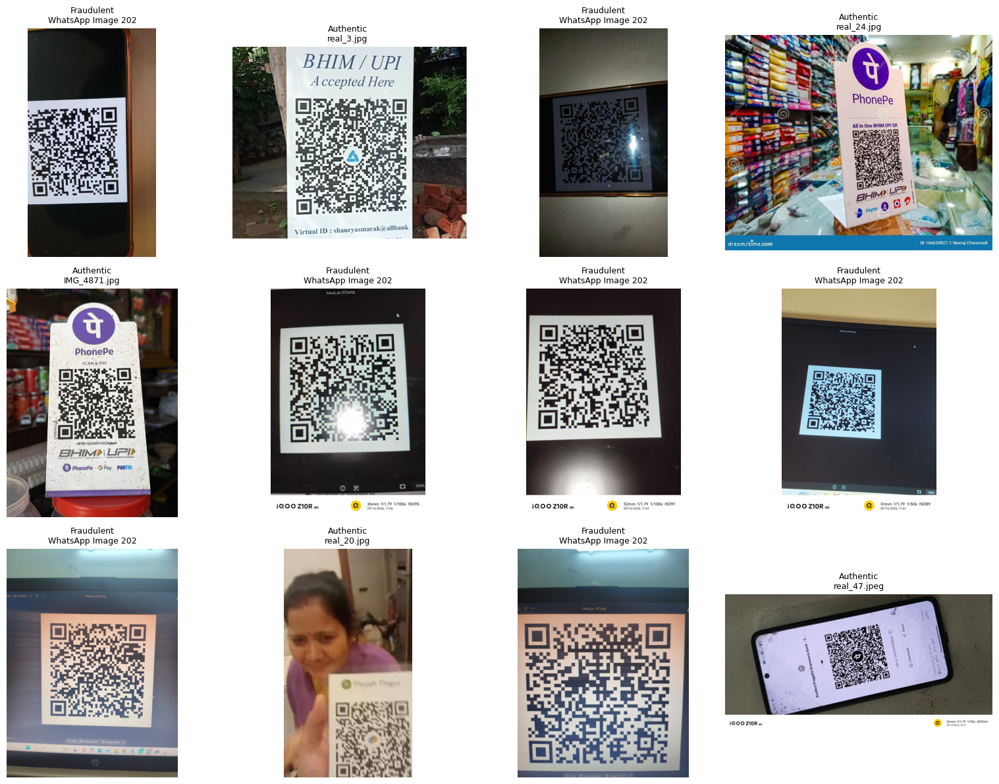

In [38]:
# ============================================
# VISUALIZE VALIDATION IMAGES
# ============================================

import matplotlib.pyplot as plt
from PIL import Image
import os

# Take only 12 validation images
sample_val = val_df.sample(
    n=min(12, len(val_df)),
    random_state=42
).reset_index(drop=True)

plt.figure(figsize=(16, 12))

for i in range(len(sample_val)):

    path = sample_val.loc[i, "path"]
    label = sample_val.loc[i, "class"]

    try:
        img = Image.open(path).convert("RGB")

        ax = plt.subplot(3, 4, i + 1)
        ax.imshow(img)

        ax.set_title(
            f"{label}\n{os.path.basename(path)[:18]}",
            fontsize=9
        )

        ax.axis("off")

    except Exception as e:
        print("ERROR:", path)
        print(e)

plt.tight_layout()
plt.show()

In [41]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomContrast(0.15),
], name="qr_augmentation")

Class: Authentic
Path: /kaggle/working/FinGuard_QR_Converted/Authentic/IMG_4883.jpg
Image size: (3024, 4032)


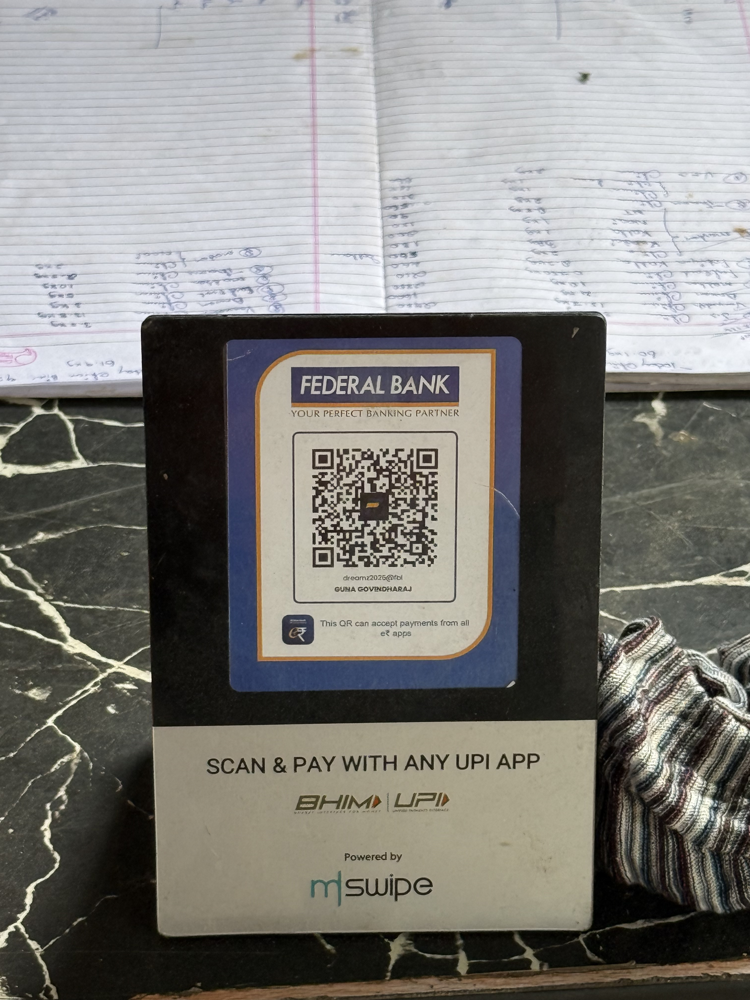

In [39]:
# ============================================
# TEST ONE VALIDATION IMAGE
# ============================================

row = val_df.iloc[0]

print("Class:", row["class"])
print("Path:", row["path"])

img = Image.open(row["path"]).convert("RGB")

print("Image size:", img.size)

display(img)

In [40]:
print("Validation images:")
print(val_df[["filename", "class"]].to_string(index=False))

Validation images:
                                         filename      class
                                     IMG_4883.jpg  Authentic
                                  IMG_4889(1).jpg  Authentic
                                     real_56.jpeg  Authentic
                                     real_47.jpeg  Authentic
      79c46c21-a9b0-4374-9f1c-f4a201e46e9c(1).jpg  Authentic
                                       real_3.jpg  Authentic
      a14e1edf-d934-4066-b089-5b3ebf2b872a(1).jpg  Authentic
                                     real_33.jpeg  Authentic
                                     IMG_6005.jpg  Authentic
                                       real_8.jpg  Authentic
                                     real_32.jpeg  Authentic
                                       real_7.jpg  Authentic
                                      real_20.jpg  Authentic
                                      real_24.jpg  Authentic
                                     real_67.jpeg  Authentic
     

In [42]:
# ============================================
# QR CUSTOM CNN
# Same architecture as Currency + Document
# ============================================

from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15),
], name="qr_augmentation")


def build_custom_cnn(input_shape=(224, 224, 3)):

    inputs = layers.Input(shape=input_shape)

    # Data augmentation
    x = data_augmentation(inputs)

    # Block 1
    x = layers.Conv2D(
        32, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2
    x = layers.Conv2D(
        64, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3
    x = layers.Conv2D(
        128, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 4
    x = layers.Conv2D(
        256, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Global Average Pooling
    x = layers.GlobalAveragePooling2D()(x)

    # Classification head
    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_QR_Custom_CNN"
    )


qr_model = build_custom_cnn()

qr_model.summary()

Model: "FinGuard_QR_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ qr_augmentation (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [43]:
# ============================================
# MODEL PARAMETERS
# ============================================

print("Total parameters:", qr_model.count_params())

print(
    "Trainable parameters:",
    sum(np.prod(v.shape) for v in qr_model.trainable_weights)
)

print(
    "Non-trainable parameters:",
    sum(np.prod(v.shape) for v in qr_model.non_trainable_weights)
)

Total parameters: 423361
Trainable parameters: 422401
Non-trainable parameters: 960


In [44]:
# ============================================
# COMPILE
# ============================================

qr_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("QR CNN compiled successfully.")

QR CNN compiled successfully.


In [45]:
# ============================================
# CALLBACKS
# ============================================

MODEL_PATH = "/kaggle/working/finguard_qr_custom_cnn.keras"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    MODEL_PATH,
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks ready.")
print("Saving best model to:", MODEL_PATH)

Callbacks ready.
Saving best model to: /kaggle/working/finguard_qr_custom_cnn.keras


In [46]:
# ============================================
# TRAIN QR CUSTOM CNN
# ============================================

history = qr_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/20
7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.4256 - auc: 0.4936 - loss: 0.7733 - precision: 0.4297 - recall: 0.2892 
Epoch 1: val_auc improved from None to 0.66322, saving model to /kaggle/working/finguard_qr_custom_cnn.keras

Epoch 1: finished saving model to /kaggle/working/finguard_qr_custom_cnn.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 488ms/step - accuracy: 0.4141 - auc: 0.4509 - loss: 0.8067 - precision: 0.4444 - recall: 0.3967 - val_accuracy: 0.5818 - val_auc: 0.6632 - val_loss: 0.6916 - val_precision: 0.5926 - val_recall: 0.9697 - learning_rate: 5.0000e-04
Epoch 2/20
7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.4349 - auc: 0.4741 - loss: 0.7419 - precision: 0.4835 - recall: 0.2294
Epoch 2: val_auc did not improve from 0.66322
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 437ms/step - accuracy: 0.4626 - auc: 0.5179 - loss: 0.7259 - precision: 0.4937 - recall: 0.3223 - val_accuracy: 0.6000 - val_auc: 0.3705 - val_loss: 0.6883 - val_precision: 0.6000 - val_recall: 1.0000 - learni

In [47]:
# ============================================
# NORMAL STRATIFIED SPLIT
# 338 UNIQUE IMAGES
# ============================================

from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    qr_unique_df,
    test_size=0.30,
    random_state=42,
    stratify=qr_unique_df["class"]
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=" * 60)
print("NORMAL STRATIFIED SPLIT")
print("=" * 60)

print("\nTRAIN")
print("Images:", len(train_df))
print(train_df["class"].value_counts())

print("\nVALIDATION")
print("Images:", len(val_df))
print(val_df["class"].value_counts())

print("\nTEST")
print("Images:", len(test_df))
print(test_df["class"].value_counts())

print("\nTOTAL:",
      len(train_df) + len(val_df) + len(test_df))

NORMAL STRATIFIED SPLIT

TRAIN
Images: 236
class
Fraudulent    131
Authentic     105
Name: count, dtype: int64

VALIDATION
Images: 51
class
Fraudulent    29
Authentic     22
Name: count, dtype: int64

TEST
Images: 51
class
Fraudulent    28
Authentic     23
Name: count, dtype: int64

TOTAL: 338


In [48]:
# ============================================
# SPLIT PROPORTIONS
# ============================================

summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Percentage": [
        len(train_df) / len(qr_unique_df) * 100,
        len(val_df) / len(qr_unique_df) * 100,
        len(test_df) / len(qr_unique_df) * 100
    ]
})

summary["Percentage"] = summary["Percentage"].round(2)

display(summary)

,Split,Images,Percentage
0,Train,236,69.82
1,Validation,51,15.09
2,Test,51,15.09


In [49]:
# ============================================
# CLASS WEIGHTS FOR NEW TRAINING SPLIT
# ============================================

label_map = {
    "Authentic": 0,
    "Fraudulent": 1
}

train_df["label"] = train_df["class"].map(label_map)
val_df["label"] = val_df["class"].map(label_map)
test_df["label"] = test_df["class"].map(label_map)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_df["label"]
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:")
print(class_weights)

Class weights:
{0: np.float64(1.1238095238095238), 1: np.float64(0.9007633587786259)}


In [50]:
# ============================================
# REBUILD DATASETS
# ============================================

train_ds = make_dataset(
    train_df,
    training=True
)

val_ds = make_dataset(
    val_df,
    training=False
)

test_ds = make_dataset(
    test_df,
    training=False
)

print("Train batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 8
Validation batches: 2
Test batches: 2


In [51]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="qr_augmentation")


def build_custom_cnn(input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)

    x = data_augmentation(inputs)

    x = layers.Conv2D(32, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2,2))(x)

    x = layers.Conv2D(64, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2,2))(x)

    x = layers.Conv2D(128, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2,2))(x)

    x = layers.Conv2D(256, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_QR_Custom_CNN"
    )


qr_model = build_custom_cnn()

qr_model.summary()

Model: "FinGuard_QR_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ qr_augmentation (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [52]:
qr_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [53]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "/kaggle/working/finguard_qr_custom_cnn.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [54]:
history = qr_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.6613 - auc: 0.7057 - loss: 0.6230 - precision: 0.6449 - recall: 0.9376
Epoch 1: val_auc improved from None to 0.53135, saving model to /kaggle/working/finguard_qr_custom_cnn.keras

Epoch 1: finished saving model to /kaggle/working/finguard_qr_custom_cnn.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 600ms/step - accuracy: 0.6949 - auc: 0.7773 - loss: 0.5946 - precision: 0.6686 - recall: 0.8931 - val_accuracy: 0.5686 - val_auc: 0.5313 - val_loss: 0.6859 - val_precision: 0.5686 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.7774 - auc: 0.8640 - loss: 0.4801 - precision: 0.8174 - recall: 0.7633
Epoch 2: val_auc improved from 0.53135 to 0.58307, saving model to /kaggle/working/finguard_qr_custom_cnn.keras

Epoch 2: finished saving model to /kaggle/working/finguard_qr_custom_cnn.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 426ms/step - accuracy: 0.7924 - auc: 0.8675 - loss: 0.4753 - pre

In [55]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)
import numpy as np
import time

# Get predictions
y_true = []
y_prob = []

for images, labels in test_ds:
    probs = qr_model.predict(images, verbose=0).ravel()

    y_prob.extend(probs)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("QR CUSTOM CNN TEST RESULTS")
print("=" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Authentic", "Fraudulent"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

QR CUSTOM CNN TEST RESULTS
Accuracy : 0.6667
ROC-AUC  : 0.7484

Classification Report:
              precision    recall  f1-score   support

   Authentic     0.6000    0.7826    0.6792        23
  Fraudulent     0.7619    0.5714    0.6531        28

    accuracy                         0.6667        51
   macro avg     0.6810    0.6770    0.6662        51
weighted avg     0.6889    0.6667    0.6649        51


Confusion Matrix:
[[18  5]
 [12 16]]


In [56]:
import os
import time
import numpy as np

# Parameter count
print("Parameters:", qr_model.count_params())

# Model size
model_path = "/kaggle/working/finguard_qr_custom_cnn.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"Model size: {size_mb:.2f} MB")
else:
    print("Model file not found:", model_path)

# Inference timing
images, labels = next(iter(test_ds))

# Warm-up
_ = qr_model.predict(images, verbose=0)

times = []

for _ in range(20):
    start = time.perf_counter()
    _ = qr_model.predict(images, verbose=0)
    end = time.perf_counter()

    batch_time = end - start
    per_image = batch_time / images.shape[0]
    times.append(per_image * 1000)

print(f"Average inference time: {np.mean(times):.2f} ms/image")
print(f"Median inference time: {np.median(times):.2f} ms/image")

Parameters: 423361
Model size: 4.94 MB
Average inference time: 2.45 ms/image
Median inference time: 2.44 ms/image
